# Recipe Recommendation System

## Project Overview

This project explores Food.com recipe information and builds a content-based recipe recommendation system. It uses recipe characteristics such as n_ingredients, n_steps, minutes, n_ingredients, minutes, n_steps, minutes, and n_ingredients to identify recipes with similar recipeal profiles.

The workflow follows the stages of data loading, exploratory data analysis (EDA), feature preprocessing, feature scaling, nearest-neighbor search, recommendation generation, and model evaluation.

**Dataset:** `RAW_recipes.csv`

**Main tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.

> The existing Python code in this notebook has been preserved. Markdown explanations and section structure have been added to make the workflow easier to read and present.


## 1. Importing Required Libraries

The libraries below support the main tasks in this project:

- **Pandas and NumPy:** data loading, manipulation, and numerical operations.
- **Matplotlib and Seaborn:** exploratory visualizations.
- **Scikit-learn:** feature scaling and nearest-neighbor similarity search.

The following cell imports the libraries used in the notebook.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

Load the Food.com recipes file into a Pandas DataFrame. The first few rows are displayed to inspect the dataset structure and understand the available fields.

Make sure `RAW_recipes.csv` is available in the notebook's working directory, or update the file path in the existing code.


In [41]:
df = pd.read_csv('data/RAW_recipes.csv')
df.head()

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13
3,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11
4,amish tomato ketchup for canning,44061,190,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-...","[352.9, 1.0, 337.0, 23.0, 3.0, 0.0, 28.0]",5,['mix all ingredients& boil for 2 1 / 2 hours ...,my dh's amish mother raised him on this recipe...,"['tomato juice', 'apple cider vinegar', 'sugar...",8


### 2.1 Dataset Dimensions

The shape of the DataFrame reports the number of records (rows) and variables (columns). This gives an initial overview of the dataset's size.


In [5]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 231637
Number of Columns: 12


### 2.2 Dataset Information and Data Types

The `info()` output provides the column names, non-null counts, and data types. This helps identify columns that may need cleaning or conversion before analysis.


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231637 entries, 0 to 231636
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   name            231636 non-null  object
 1   id              231637 non-null  int64 
 2   minutes         231637 non-null  int64 
 3   contributor_id  231637 non-null  int64 
 4   submitted       231637 non-null  object
 5   tags            231637 non-null  object
 6   nutrition       231637 non-null  object
 7   n_steps         231637 non-null  int64 
 8   steps           231637 non-null  object
 9   description     226658 non-null  object
 10  ingredients     231637 non-null  object
 11  n_ingredients   231637 non-null  int64 
dtypes: int64(5), object(7)
memory usage: 21.2+ MB


### 2.3 Missing Value Inspection

Missing values can affect analysis and model preparation. This check identifies columns that contain null values and shows how many values are missing in each.


In [7]:
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

name              1
description    4979
dtype: int64


### 2.4 Duplicate Records and Unique Recipes

This section checks for exact duplicate rows and counts distinct recipe IDs. A recipe may appear in more than one tags entry, so the number of rows and the number of unique recipes may differ.


In [8]:
print("Duplicate Rows:", df.duplicated().sum())
print("Unique Recipes:", df["id"].nunique())

Duplicate Rows: 0
Unique Recipes: 231637


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the dataset through summary information and visualizations. The following plots examine tags representation, contributor representation, minutes, and selected recipe characteristics.

EDA helps us understand the data before selecting and preparing features for the recommendation model.


## Top 10 Recipe Tagss

### 3.1 Top 10 Recipe Tagss

This bar chart displays the ten most frequently represented tagss in the dataset. It helps identify which tagss have the largest representation.

**How to interpret it:** Longer bars indicate tagss with more records. This describes the dataset's composition; it does not necessarily represent overall recipe-listening minutes.


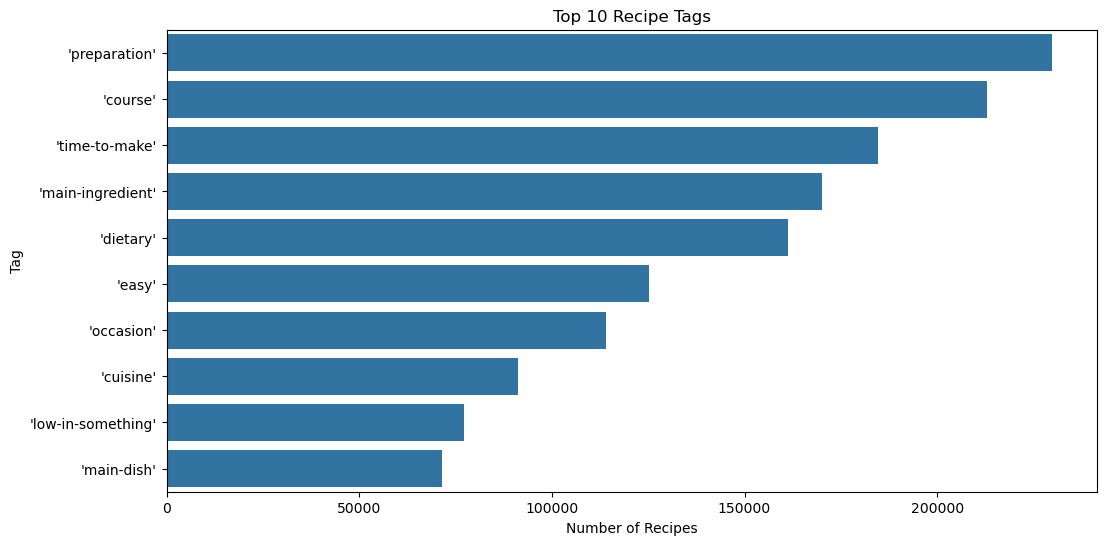

In [9]:
plt.figure(figsize=(12, 6))
top_tags = df['tags'].dropna().astype(str).str.split(',').explode().str.strip().value_counts().head(10)
sns.barplot(x=top_tags.values, y=top_tags.index)
plt.title("Top 10 Recipe Tags")
plt.xlabel("Number of Recipes")
plt.ylabel("Tag")
plt.show()

### 3.2 Top 10 Contributors by Number of Recipes

This visualization identifies the contributors with the highest number of records in the dataset.

**How to interpret it:** Contributors with longer bars have more recipes represented in this dataset. The result reflects dataset coverage, not necessarily an contributor's global minutes.


## Top 10 contributors by number of recipes

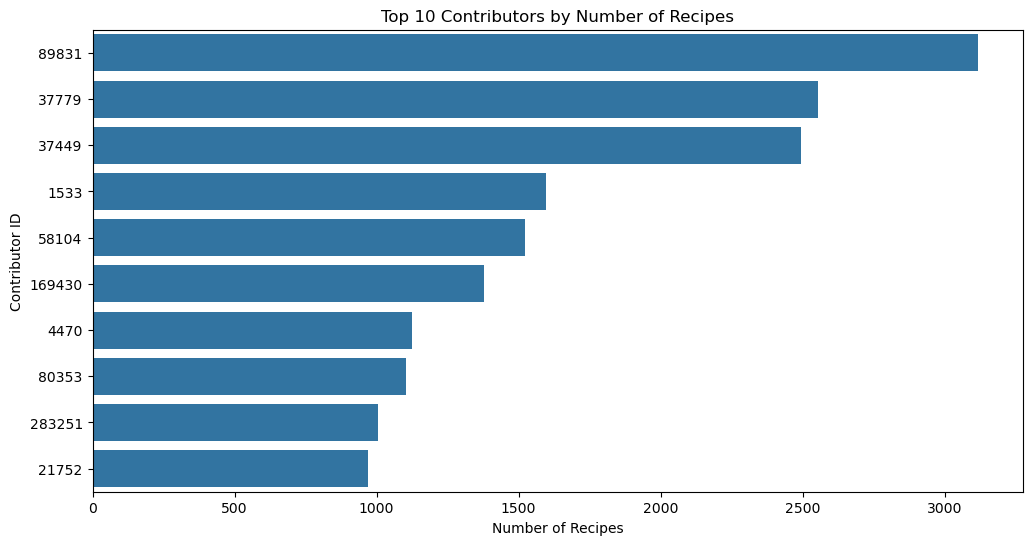

In [10]:
plt.figure(figsize=(12, 6))
top_contributors = df['contributor_id'].value_counts().head(10)
sns.barplot(x=top_contributors.values, y=top_contributors.index.astype(str))
plt.title("Top 10 Contributors by Number of Recipes")
plt.xlabel("Number of Recipes")
plt.ylabel("Contributor ID")
plt.show()

### 3.3 Recipe Cooking Time Distribution

The histogram shows how recipe minutes scores are distributed across the dataset. The KDE curve provides a smoothed view of the distribution.

**How to interpret it:** Look for where scores are concentrated, whether the distribution is skewed, and whether there are relatively few recipes at the high or low ends.


## Recipe minutes distribution

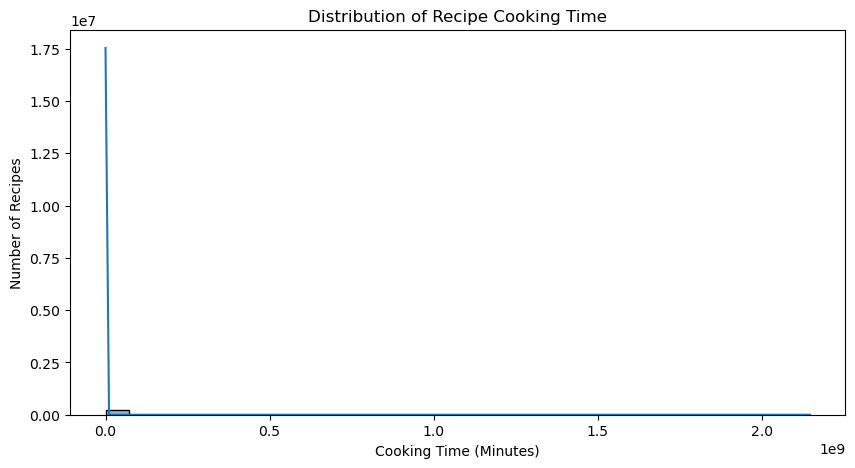

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(df['minutes'], bins=30, kde=True)
plt.title("Distribution of Recipe Cooking Time")
plt.xlabel("Cooking Time (Minutes)")
plt.ylabel("Number of Recipes")
plt.show()

### 3.4 Number of Ingredients Distribution

Number of Ingredients is an recipe feature describing how suitable a recipe is for dancing. Its score is represented on a scale from 0 to 1.

**How to interpret it:** The histogram shows whether the dataset contains more recipes with lower, moderate, or higher n_ingredients scores.


## Number of Ingredients distribution

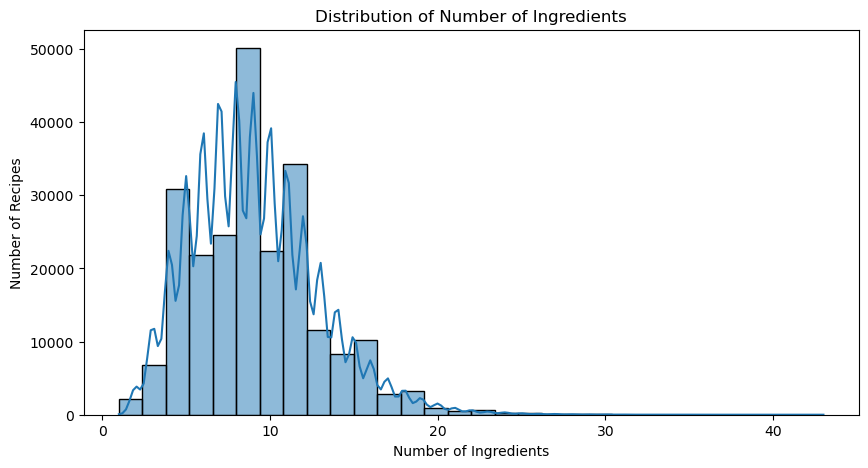

In [12]:
plt.figure(figsize=(10, 5))
sns.histplot(df['n_ingredients'], bins=30, kde=True)
plt.title("Distribution of Number of Ingredients")
plt.xlabel("Number of Ingredients")
plt.ylabel("Number of Recipes")
plt.show()

### 3.5 Relationship Between Number of Steps and Number of Ingredients

The scatter plot compares n_steps and n_ingredients for a sample of 5,000 records. Sampling makes the visualization easier to inspect while retaining a reproducible selection through the fixed random state.

**How to interpret it:** Each point represents a recipe. A visible pattern may suggest an association between n_steps and n_ingredients, while a diffuse cloud suggests a weaker relationship.


## Number of Steps vs Number of Ingredients

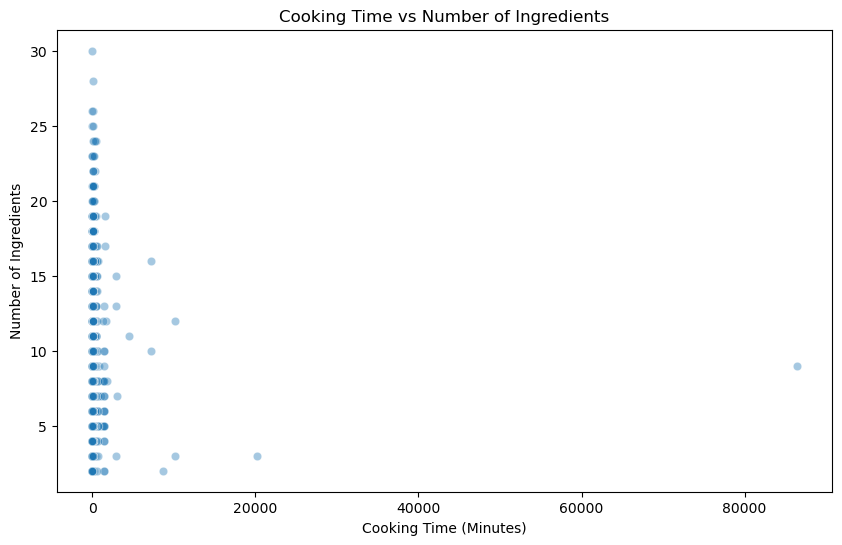

In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=42), x='minutes', y='n_ingredients', alpha=0.4)
plt.title("Cooking Time vs Number of Ingredients")
plt.xlabel("Cooking Time (Minutes)")
plt.ylabel("Number of Ingredients")
plt.show()

### 3.6 Correlation Between Recipe Features

A correlation heatmap summarizes pairwise linear relationships between the selected numerical variables, including minutes.

Correlation values range from -1 to +1:

- **+1:** strong positive linear relationship.
- **0:** little or no linear relationship.
- **-1:** strong negative linear relationship.

Correlation describes association, not causation. The heatmap is an exploratory tool for understanding how the features relate to one another.


## Recipe feature correlation

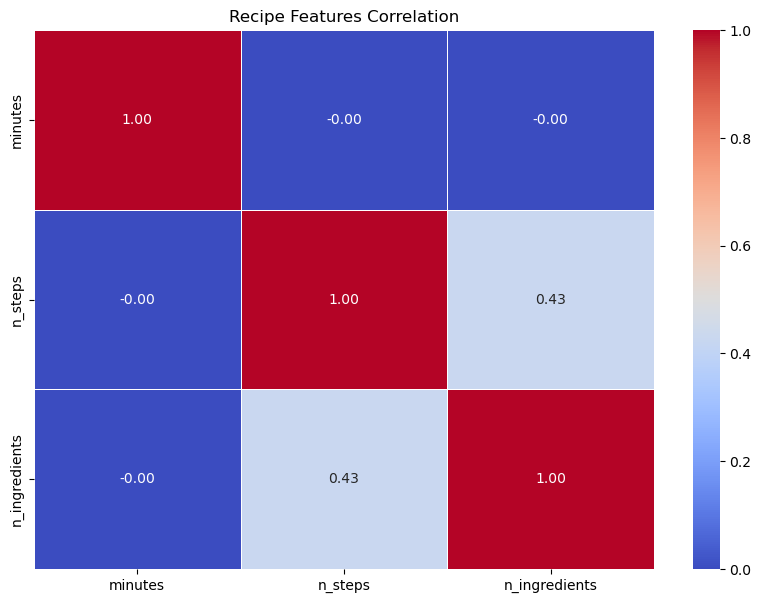

In [14]:
recipe_features = ['minutes', 'n_steps', 'n_ingredients']
plt.figure(figsize=(10, 7))
correlation = df[recipe_features].apply(pd.to_numeric, errors='coerce').corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Recipe Features Correlation")
plt.show()

## 4. Feature Preprocessing

Feature preprocessing prepares the dataset for the recommendation algorithm. In this project, the model uses numerical recipe characteristics to compare recipes.

The steps below select the recipe features, inspect and handle missing values, retain one record per recipe ID, and standardize the selected features.


# Feature Preprocessing

### 4.1 Selecting Recipe Features

The selected features describe different aspects of a recipe's sound. They will be used as input variables for similarity calculations.

The project uses nine recipe features: n_ingredients, n_steps, minutes, n_ingredients, n_steps, minutes, n_steps, minutes, and n_ingredients.


### Create a list of recipe features

In [15]:
recipe_features = ['minutes', 'n_steps', 'n_ingredients']
print("Selected Recipe Features:")
print(recipe_features)
print("\nTotal Features:", len(recipe_features))

Selected Recipe Features:
['minutes', 'n_steps', 'n_ingredients']

Total Features: 3


### 4.2 Inspecting and Handling Missing Values

First, inspect missing values in the selected recipe features. The following code then converts these columns to numeric values and fills missing entries with the median of the corresponding feature.

Using the median provides a simple way to retain rows while filling missing numerical values.


### Handle missing values

In [16]:
print("Missing Values Before Cleaning:\n")
print(df[recipe_features].isnull().sum())

Missing Values Before Cleaning:

minutes          0
n_steps          0
n_ingredients    0
dtype: int64


In [17]:
df[recipe_features] = df[recipe_features].apply(pd.to_numeric, errors='coerce')
df[recipe_features] = df[recipe_features].fillna(df[recipe_features].median())
print("Missing Values After Cleaning:")
print(df[recipe_features].isnull().sum().sum())

Missing Values After Cleaning:
0


### 4.3 Removing Duplicate Recipes

The dataset can contain multiple records associated with the same recipe ID. For this recommendation workflow, the code retains the first occurrence of each recipe ID.

This creates `df_model`, the recipe-level DataFrame used by the recommendation model. The original `df` remains available for the earlier EDA.


### Remove duplicate recipes

In [18]:
print("Before Removing Duplicates:", df.shape)
df_model = df.drop_duplicates(subset=['id']).copy()
df_model = df_model.dropna(subset=['name']).reset_index(drop=True)
print("After Removing Duplicates:", df_model.shape)
print("Unique Recipe IDs:", df_model['id'].nunique())

Before Removing Duplicates: (231637, 12)
After Removing Duplicates: (231636, 12)
Unique Recipe IDs: 231636


### 4.4 Feature Scaling Using StandardScaler

The selected recipe features use different numerical ranges. For example, minutes is measured in beats per minute, while n_ingredients and n_steps are bounded scores.

`StandardScaler` standardizes each selected feature by centering it around a mean of approximately zero and scaling it to a standard deviation of approximately one. This helps prevent features with larger numerical ranges from dominating distance calculations solely because of their units.


### Feature scaling using StandardScaler

In [19]:
scaler = StandardScaler()
features_scaled = scaler.fit_transform(df_model[recipe_features])
print("Feature Scaling Completed!")
print("Scaled Features Shape:", features_scaled.shape)

Feature Scaling Completed!
Scaled Features Shape: (231636, 3)


### 4.5 Inspecting the Scaled Features

The scaled NumPy array is converted into a DataFrame so that the standardized feature values can be inspected with familiar column labels.


### Convert scaled features into a DataFrame

In [27]:
scaled_df = pd.DataFrame(features_scaled, columns=recipe_features)
scaled_df.head()

,minutes,n_steps,n_ingredients
0,-0.002094,0.205915,-0.549200
1,-0.002100,-0.127690,-0.816952
2,-0.002077,-0.628097,1.057314
3,-0.002096,0.205915,0.521809
4,-0.002064,-0.794899,-0.281448


### 4.6 Verifying Feature Scaling

This check displays the mean and standard deviation of each scaled feature. The means should be close to zero and the standard deviations should be close to one (small display or floating-point differences are normal).


### Verify feature scaling

In [21]:
print("Feature Means:\n")
print(scaled_df.mean().round(2))
print("\nFeature Standard Deviations:\n")
print(scaled_df.std().round(2))

Feature Means:

minutes          0.0
n_steps         -0.0
n_ingredients    0.0
dtype: float64

Feature Standard Deviations:

minutes          1.0
n_steps          1.0
n_ingredients    1.0
dtype: float64


## 5. Building the Similarity Search Model

A full pairwise cosine-similarity matrix for a large recipe collection can require substantial memory. Instead, this notebook uses Scikit-learn's `NearestNeighbors` with the cosine distance metric.

The model is fitted on the standardized recipe features. When a recipe is queried, it finds nearby recipes in the feature space without storing a complete all-by-all similarity matrix.


# Calculate Cosine Similarity

### 5.1 Fit the Nearest Neighbors Model

The model is configured to use cosine distance and brute-force neighbor search. The requested number of neighbors is 11 so that the selected recipe itself can be returned alongside up to ten other close matches.


In [22]:
model = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=11, n_jobs=-1)
model.fit(features_scaled)
print("Nearest Neighbors Model Trained Successfully!")

Nearest Neighbors Model Trained Successfully!


### 5.2 Inspecting Nearest Neighbors

This test queries the model using the first recipe in the prepared dataset.

- `indices` contains the row positions of the nearest recipes.
- `distances` contains the corresponding cosine distances.

The selected recipe normally appears first with a distance very close to zero. Smaller cosine distances indicate more similar feature vectors.


In [23]:
distances, indices = model.kneighbors(features_scaled[0].reshape(1, -1))
print("Recommended Recipe Indices:")
print(indices)
print("\nCosine Distances:")
print(distances)

Recommended Recipe Indices:
[[ 50628 175428 201852  15364  38741 164299 134497 177321      0  28051
  129333]]

Cosine Distances:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


## 6. Creating the Recipe Recommendation Function

The recommendation function accepts a recipe name, locates the corresponding record, and queries the fitted nearest-neighbor model.

It removes the selected recipe from the returned results, retrieves the recommended recipes' metadata, and converts cosine distance into a similarity percentage using:

**Similarity (%) = (1 − cosine distance) × 100**

This percentage expresses similarity in the selected recipe-feature space; it is not a measure of listener preference.


In [29]:
def recommend_recipes(recipe_name, top_n=10):
    recipe_match = df_model[df_model['name'].str.lower() == recipe_name.lower()]
    if recipe_match.empty:
        print("Recipe not found. Please try another recipe.")
        return
    recipe_index = recipe_match.index[0]
    distances, indices = model.kneighbors(features_scaled[recipe_index].reshape(1, -1), n_neighbors=top_n + 1)
    recommended_indices = indices[0][1:]
    recommended_distances = distances[0][1:]
    recommendations = df_model.iloc[recommended_indices][['name', 'minutes', 'n_ingredients']].copy()
    recommendations['Similarity Score'] = ((1 - recommended_distances) * 100).round(2)
    print(f"\nRecipes similar to: {recipe_name}\n")
    return recommendations.reset_index(drop=True)

### 6.1 Testing the Recommendation Function

The following cell tests the function with a recipe name from the dataset and requests ten recommendations. Review the returned recipe names, contributors, tagss, minutes values, and similarity scores.


In [30]:
recommend_recipes(df_model.iloc[0]['name'], top_n=10)


Recipes similar to: arriba   baked winter squash mexican style



,name,minutes,n_ingredients,Similarity Score
0,roasted coriander carrots,55,7,100.0
1,stuffed butternut squash,55,7,100.0
2,baked swiss chicken over tri colored spiral pasta,55,7,100.0
3,cheater s new york style cheesecake,55,7,100.0
4,possum s cream cheese chocolate chip bread,55,7,100.0
5,mexican poached guavas,55,7,100.0
6,rosemary roast chicken with smothered potatoes,55,7,100.0
7,arriba baked winter squash mexican style,55,7,100.0
8,bread and butter pudding ii,55,7,100.0
9,mandarin orange tea cake,55,7,100.0


### 6.2 Recommendation Function with Selected Recipe Details

This version of the recommendation function also displays the selected recipe's title, contributor, and tags before returning the recommendations. It retains the same nearest-neighbor approach.


In [31]:
def recommend_recipes(recipe_name, top_n=10):
    recipe_match = df_model[df_model['name'].str.lower() == recipe_name.lower()]
    if recipe_match.empty:
        print("Recipe not found.")
        return
    recipe_index = recipe_match.index[0]
    selected_recipe = df_model.iloc[recipe_index]
    distances, indices = model.kneighbors(features_scaled[recipe_index].reshape(1, -1), n_neighbors=top_n + 1)
    recommended_indices = indices[0][1:]
    recommended_distances = distances[0][1:]
    recommendations = df_model.iloc[recommended_indices][['name', 'minutes', 'n_ingredients']].copy()
    recommendations['Similarity Score'] = ((1 - recommended_distances) * 100).round(2)
    print("Selected Recipe:", selected_recipe['name'])
    print("Cooking Time:", selected_recipe['minutes'])
    print("Number of Ingredients:", selected_recipe['n_ingredients'])
    return recommendations.reset_index(drop=True)

## 7. Model Evaluation and Recommendation Inspection

The following checks provide simple diagnostics for the recommendation results. They examine tags consistency and average similarity for one selected recipe.

These are exploratory evaluation measures rather than a complete assessment of user satisfaction. A recommendation can be recipeally similar according to the selected recipe features without necessarily matching a listener's personal taste.


In [32]:
def evaluate_recommendations(recipe_name, top_n=10):
    recipe = df_model[df_model['name'].str.lower() == recipe_name.lower()]
    if recipe.empty:
        print("Recipe not found!")
        return
    recommendations = recommend_recipes(recipe_name, top_n)
    avg_similarity = recommendations['Similarity Score'].mean()
    print("\n--- MODEL EVALUATION ---")
    print("Selected Recipe:", recipe.iloc[0]['name'])
    print("Average Similarity:", round(avg_similarity, 2), "%")

### 7.1 Evaluate Tags Consistency and Average Similarity

The evaluation compares each recommended recipe's tags with the selected recipe's tags and calculates the average similarity score.

Tags consistency is a strict same-label comparison. It should be interpreted carefully because recipes with different tags labels can still have similar recipe characteristics.


In [33]:
evaluate_recommendations(df_model.iloc[0]['name'], top_n=10)

Selected Recipe: arriba   baked winter squash mexican style
Cooking Time: 55
Number of Ingredients: 7

--- MODEL EVALUATION ---
Selected Recipe: arriba   baked winter squash mexican style
Average Similarity: 100.0 %


### 7.2 Compare Recipe Features of the Selected and Recommended Recipes

This section gathers the original, unscaled recipe feature values for the selected recipe and its ten nearest recommendations.

The resulting table makes it possible to inspect the actual feature values rather than only the combined similarity score.


In [34]:
recipe_name = df_model.iloc[0]['name']
recipe_index = df_model[df_model['name'].str.lower() == recipe_name.lower()].index[0]
distances, indices = model.kneighbors(features_scaled[recipe_index].reshape(1, -1), n_neighbors=11)
recommended_indices = indices[0][1:]
comparison_indices = [recipe_index] + list(recommended_indices)
comparison_df = df_model.iloc[comparison_indices][recipe_features].copy()
comparison_df.index = ['Selected Recipe'] + [f'Recommended {i}' for i in range(1, 11)]
comparison_df.head(11)

,minutes,n_steps,n_ingredients
Selected Recipe,55,11,7
Recommended 1,55,11,7
Recommended 2,55,11,7
Recommended 3,55,11,7
Recommended 4,55,11,7
Recommended 5,55,11,7
Recommended 6,55,11,7
Recommended 7,55,11,7
Recommended 8,55,11,7
Recommended 9,55,11,7


### 7.3 Visualize Recipe Feature Comparisons

The bar chart compares the selected recipe's recipe features with those of the recommended recipes.

Because the chart uses original feature values, the features have different scales. Use it to inspect individual feature patterns, while remembering that the recommendation model calculated distances using standardized values.


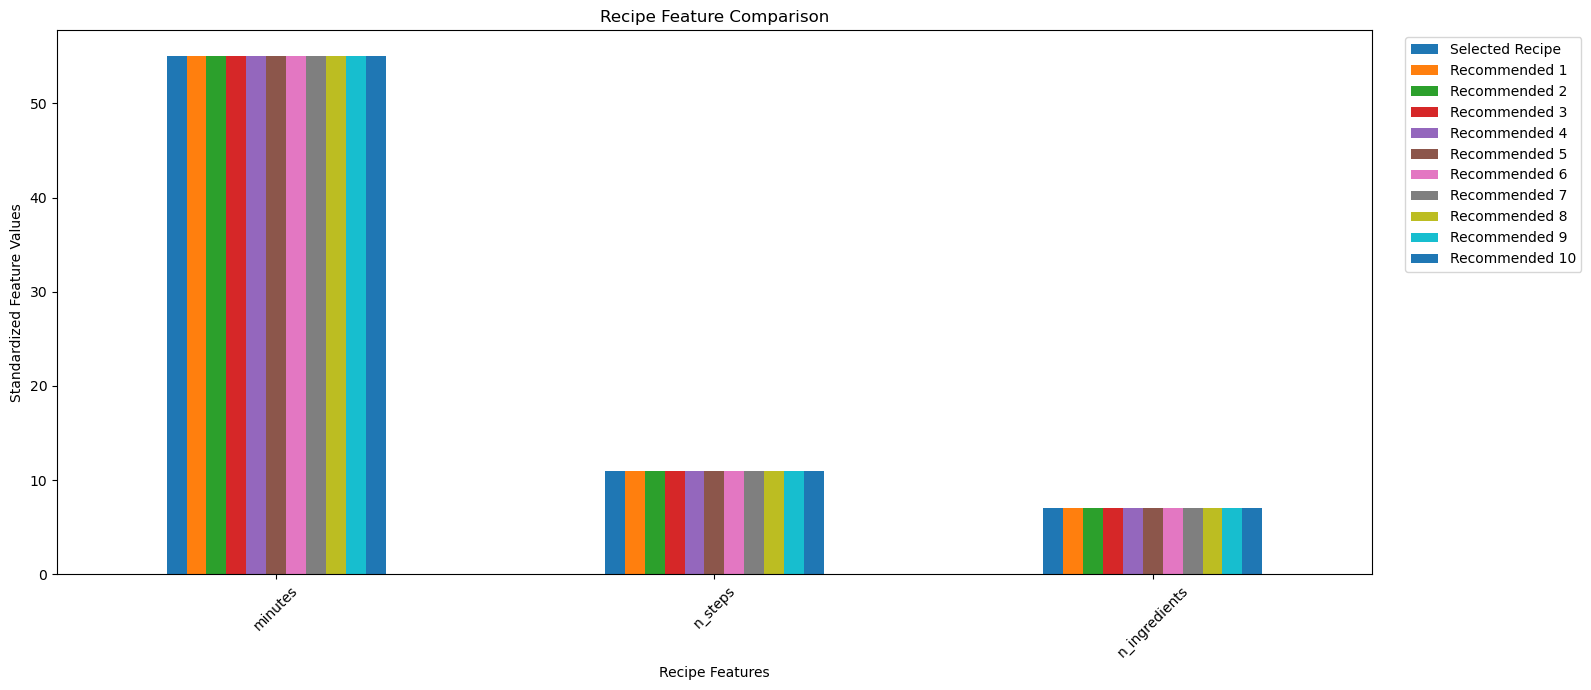

In [35]:
comparison_df.T.plot(kind='bar', figsize=(16, 7))
plt.title("Recipe Feature Comparison")
plt.xlabel("Recipe Features")
plt.ylabel("Standardized Feature Values")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 8. Streamlit Application

The final section contains the Streamlit application source. It is written to a Python file using the notebook's existing cell magic.

The application loads the Food.com CSV, prepares the recipe features, fits a nearest-neighbor model, and provides a recipe search interface for displaying recommendations.

To run the resulting application, ensure the CSV file is in the expected working directory and run the generated Python script with Streamlit from a terminal.


In [42]:
%%writefile Recipe.py

import streamlit as st
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# ---------------- PAGE CONFIG ----------------

st.set_page_config(
    page_title="Recipe Recommender",
    page_icon="🍲",
    layout="wide"
)

# ---------------- CUSTOM CSS ----------------

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700;800&display=swap');

html, body, [class*="css"] {
    font-family: 'DM Sans', sans-serif;
}

.stApp {
    background-color: #F8F8F2;
}

.block-container {
    padding: 2rem 5rem 3rem 5rem;
    max-width: 1400px;
}

header {
    background: transparent !important;
}

.hero {
    background: linear-gradient(120deg, #153D2B, #286044);
    padding: 55px 50px;
    border-radius: 24px;
    color: white;
    margin-bottom: 35px;
}

.hero h1 {
    color: white;
    font-size: 43px;
    font-weight: 800;
    margin-bottom: 12px;
}

.hero p {
    color: #DCE9DF;
    font-size: 17px;
    margin-bottom: 0;
}

.section-title {
    color: #193D2B;
    font-size: 25px;
    font-weight: 800;
    margin: 25px 0 15px 0;
}

.search-box {
    background: white;
    padding: 28px;
    border-radius: 18px;
    border: 1px solid #E6E9E1;
    margin-bottom: 25px;
}

div[data-testid="stTextInput"] input,
div[data-testid="stSelectbox"] div[data-baseweb="select"] {
    border-radius: 10px;
}

.stButton > button {
    background: #1D5538;
    color: white;
    border: none;
    border-radius: 10px;
    padding: 12px 25px;
    font-weight: 700;
    width: 100%;
    transition: 0.2s;
}

.stButton > button:hover {
    background: #286C48;
    color: white;
    border: none;
}

.metric-card {
    background: white;
    padding: 22px;
    border-radius: 16px;
    border: 1px solid #E6E9E1;
    text-align: center;
}

.metric-label {
    color: #718071;
    font-size: 13px;
    font-weight: 600;
}

.metric-value {
    color: #1D5538;
    font-size: 30px;
    font-weight: 800;
    margin-top: 5px;
}

.recipe-card {
    background: white;
    border: 1px solid #E5E9E1;
    border-radius: 16px;
    padding: 22px;
    margin-bottom: 15px;
    min-height: 155px;
    box-shadow: 0 3px 12px rgba(20, 50, 30, 0.04);
}

.recipe-card h4 {
    color: #193D2B;
    font-size: 17px;
    margin-bottom: 12px;
}

.recipe-detail {
    color: #68766A;
    font-size: 13px;
    margin-bottom: 8px;
}

.similarity {
    color: #1D7045;
    font-weight: 800;
    font-size: 14px;
}

.footer {
    text-align: center;
    color: #829083;
    font-size: 13px;
    padding: 30px 0 10px 0;
}

</style>
""", unsafe_allow_html=True)


# ---------------- HEADER ----------------

st.markdown("""
<div class="hero">
    <h1>🍲 Discover Your Next Favourite Meal</h1>
    <p>Explore recipes and find dishes similar to the ones you already love.</p>
</div>
""", unsafe_allow_html=True)


# ---------------- MODEL ----------------

recipe_features = ['minutes', 'n_steps', 'n_ingredients']


@st.cache_resource
def load_model():

    base_dir = Path(__file__).resolve().parent

    data_path = base_dir / "data" / "RAW_recipes.csv"

    if not data_path.exists():
        raise FileNotFoundError(
            f"Dataset not found at: {data_path}"
        )

    data = pd.read_csv(data_path)

    data = (
        data.dropna(subset=['id', 'name'])
        .drop_duplicates(subset=['id'])
        .reset_index(drop=True)
    )

    for col in recipe_features:
        data[col] = pd.to_numeric(data[col], errors='coerce')
        data[col] = data[col].fillna(data[col].median())

    scaler = StandardScaler()
    scaled = scaler.fit_transform(data[recipe_features])

    knn = NearestNeighbors(
        metric='cosine',
        algorithm='brute',
        n_neighbors=11,
        n_jobs=-1
    )

    knn.fit(scaled)

    return data, scaled, knn


df, features_scaled, model = load_model()


# ---------------- SEARCH SECTION ----------------

st.markdown(
    '<div class="section-title">Find a Recipe</div>',
    unsafe_allow_html=True
)

st.markdown('<div class="search-box">', unsafe_allow_html=True)

recipe_name = st.text_input(
    "Search by recipe name",
    placeholder="Example: Arrabbiata, Pasta, Chocolate Cake..."
)

if recipe_name:

    matches = df[
        df['name'].str.contains(
            recipe_name,
            case=False,
            na=False,
            regex=False
        )
    ]

    if matches.empty:

        st.warning("No matching recipes found. Try another recipe name.")

    else:

        options = {
            f"{row['name']} (ID: {row['id']})": index
            for index, row in matches.iterrows()
        }

        selected_recipe = st.selectbox(
            "Select your recipe",
            list(options.keys())
        )

        if st.button("✨ Find Similar Recipes"):

            recipe_index = options[selected_recipe]

            recipe = df.iloc[recipe_index]

            st.markdown(
                '<div class="section-title">Your Selected Recipe</div>',
                unsafe_allow_html=True
            )

            st.success(f"Showing recipes similar to {recipe['name']}")

            # Recipe statistics

            col1, col2, col3 = st.columns(3)

            with col1:
                st.markdown(f"""
                <div class="metric-card">
                    <div class="metric-label">COOKING TIME</div>
                    <div class="metric-value">{recipe['minutes']}</div>
                    <div class="metric-label">Minutes</div>
                </div>
                """, unsafe_allow_html=True)

            with col2:
                st.markdown(f"""
                <div class="metric-card">
                    <div class="metric-label">INGREDIENTS</div>
                    <div class="metric-value">{recipe['n_ingredients']}</div>
                    <div class="metric-label">Ingredients</div>
                </div>
                """, unsafe_allow_html=True)

            with col3:
                st.markdown(f"""
                <div class="metric-card">
                    <div class="metric-label">PREPARATION STEPS</div>
                    <div class="metric-value">{recipe['n_steps']}</div>
                    <div class="metric-label">Steps</div>
                </div>
                """, unsafe_allow_html=True)

            # ---------------- RECOMMENDATIONS ----------------

            distances, indices = model.kneighbors(
                features_scaled[recipe_index].reshape(1, -1),
                n_neighbors=11
            )

            recommended_indices = indices[0][1:]
            recommended_distances = distances[0][1:]

            recommendations = df.iloc[
                recommended_indices
            ][['name', 'minutes', 'n_ingredients']].copy()

            recommendations['Similarity'] = (
                (1 - recommended_distances) * 100
            ).round(2)

            st.markdown(
                '<div class="section-title">🍽️ Recommended Recipes</div>',
                unsafe_allow_html=True
            )

            st.caption(
                "Here are 10 recipes with similar characteristics."
            )

            # Display recommendations as cards

            for i in range(0, len(recommendations), 2):

                cols = st.columns(2)

                for j in range(2):

                    if i + j < len(recommendations):

                        row = recommendations.iloc[i + j]

                        with cols[j]:

                            st.markdown(f"""
                            <div class="recipe-card">
                                <h4>🍴 {row['name']}</h4>
                                <div class="recipe-detail">
                                    ⏱️ Cooking time: {row['minutes']} minutes
                                </div>
                                <div class="recipe-detail">
                                    🥗 Ingredients: {row['n_ingredients']}
                                </div>
                                <div class="similarity">
                                    ✦ {row['Similarity']}% Similarity
                                </div>
                            </div>
                            """, unsafe_allow_html=True)


st.markdown('</div>', unsafe_allow_html=True)


# ---------------- FOOTER ----------------

st.markdown("""
<div class="footer">
    <p>🍲 Recipe Recommender</p>
    <p>Powered by Python · Pandas · Scikit-learn · Streamlit</p>
</div>
""", unsafe_allow_html=True)


Overwriting Recipe.py


## 9. Project Conclusion

This notebook demonstrates a content-based recipe recommendation workflow using Food.com recipe recipe features.

The project covers:

1. Loading and inspecting the Food.com dataset.
2. Exploring tags, contributor, minutes, and recipe-feature distributions.
3. Selecting and preprocessing numerical recipe features.
4. Standardizing features with `StandardScaler`.
5. Finding similar recipes with cosine distance and `NearestNeighbors`.
6. Generating recipe recommendations and inspecting their tags and recipe-feature characteristics.
7. Providing a Streamlit interface for interactive recommendations.

### Limitations and Future Improvements

- The recommendations are based on the nine selected recipe features and do not use lyrics, listening history, or user feedback.
- Similarity scores indicate proximity in the standardized feature space; they should not be interpreted as a guarantee that a listener will like a recipe.
- Tags labels can be broad or inconsistent, so tags consistency is only a basic diagnostic.
- Future improvements could include user feedback, tags-aware filtering, recommendation diversity, recipe artwork, and links to official streaming pages.

**Outcome:** A content-based Food.com recipe recommendation prototype built with Python and Scikit-learn.
